<a href="https://colab.research.google.com/github/Renu-122/ML-programs/blob/main/ML_program.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#step 1: import all the libaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
data = pd.read_csv('student_dataset.csv')
print(data)
#step 2: import the csv file
print(data.head()) #to get first few records
print(data.shape) # to get no. of rows and columns
print(data.columns) #check column names

    Student_ID    Name  Age  Gender  Study_Hours  Attendance  Assignments  \
0            1   Aarav   19    Male          5.5        92.0          8.0   
1            2    Diya   20  Female          7.0        95.0          9.0   
2            3   Rohan   18    Male          3.5        78.0          6.0   
3            4  Ananya   19  Female          6.0        88.0          8.0   
4            5  Vikram   21    Male          4.0        75.0          7.0   
5            6   Meera   20  Female          8.0        98.0         10.0   
6            7   Arjun   19    Male          NaN        85.0          7.0   
7            8   Sneha   18  Female          6.5        90.0          NaN   
8            9   Karan   22    Male          2.5        65.0          5.0   
9           10  Ishita   20  Female          7.5        94.0          9.0   
10          11   Rahul   21    Male          4.5         NaN          6.0   
11          12   Priya   19  Female          5.0        87.0          8.0   

In [ ]:
#step 3: understanding the dataset
print(data.dtypes)
print(data.describe())
print(data.isnull().sum())
print(data.duplicated().sum()) # TO CHECK DUPLICATE RECORDS

Student_ID       int64
Name            object
Age              int64
Gender          object
Study_Hours    float64
Attendance     float64
Assignments    float64
Exam_Score       int64
Result          object
dtype: object
       Student_ID        Age  Study_Hours  Attendance  Assignments  Exam_Score
count    20.00000  20.000000    19.000000   19.000000    19.000000   20.000000
mean     10.50000  19.650000     5.473684   86.052632     7.578947   80.300000
std       5.91608   1.268028     1.751774    9.312320     1.502435   10.926067
min       1.00000  18.000000     2.500000   65.000000     5.000000   60.000000
25%       5.75000  19.000000     4.000000   79.000000     6.500000   71.500000
50%      10.50000  19.500000     5.500000   88.000000     8.000000   81.500000
75%      15.25000  20.250000     6.750000   92.500000     8.500000   88.500000
max      20.00000  22.000000     8.500000   99.000000    10.000000   98.000000
Student_ID     0
Name           0
Age            0
Gender         0


In [ ]:
#step 4: PERFORM data cleaning
data["Study_Hours"]=data["Study_Hours"].fillna(data["Study_Hours"].mean())
data["Assignments"]=data["Assignments"].fillna(data["Assignments"].mean())
print(data.isnull().sum())

Student_ID     0
Name           0
Age            0
Gender         0
Study_Hours    0
Attendance     1
Assignments    0
Exam_Score     0
Result         0
dtype: int64


In [ ]:
pd.read_excel("student_dataset.xlsx").to_csv("student_dataset.csv",index=False)

In [ ]:
#step 5: remove duplicates
data=data.drop_duplicates()
print(data.duplicated().sum())

0


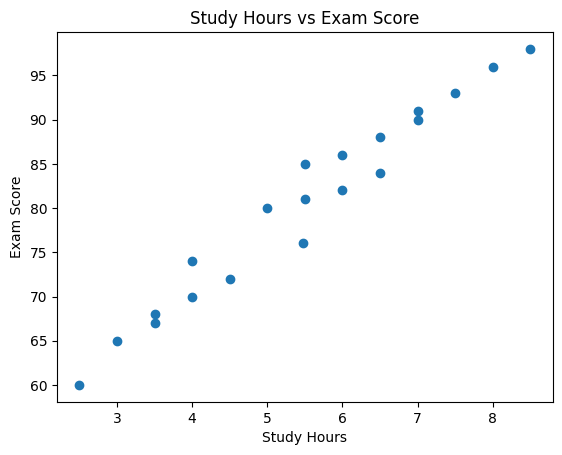

In [ ]:
#step 6: perform basic data visualization

plt.scatter(data["Study_Hours"],data["Exam_Score"])
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")
plt.show()

In [ ]:
#step 7:feature Engineering

data["Performance Score"]=(0.4*data["Exam_Score"]+0.3*data["Study_Hours"]+0.3*data["Assignments"])

print(data.head())

   Student_ID    Name  Age  Gender  Study_Hours  Attendance  Assignments  \
0           1   Aarav   19    Male          5.5        92.0          8.0   
1           2    Diya   20  Female          7.0        95.0          9.0   
2           3   Rohan   18    Male          3.5        78.0          6.0   
3           4  Ananya   19  Female          6.0        88.0          8.0   
4           5  Vikram   21    Male          4.0        75.0          7.0   

   Exam_Score Result  Performance Score  
0          85   Pass              38.05  
1          91   Pass              41.20  
2          68   Pass              30.05  
3          82   Pass              37.00  
4          70   Pass              31.30  


In [ ]:
#step 8: separate features amd Target

X=data[
    ["Study_Hours","Attendance","Exam_Score","Assignments"]
]
y=data["Result"]
print(X.head())


   Study_Hours  Attendance  Exam_Score  Assignments
0          5.5        92.0          85          8.0
1          7.0        95.0          91          9.0
2          3.5        78.0          68          6.0
3          6.0        88.0          82          8.0
4          4.0        75.0          70          7.0


In [ ]:
#step 9:to convert the data


y=y.map({"Fail":0 ,"Pass":1})
print(y.head())

0    1
1    1
2    1
3    1
4    1
Name: Result, dtype: int64


In [ ]:
#step 10: Split the dataset

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

#80%->Training data,20%->Testing
print("Training set shape:",X_train.shape)

Training set shape: (16, 4)


In [ ]:
#step 11:select a ML algorithm

#lets use a Decision Tree Classifier

model=DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

In [ ]:
#step 12:train the model
model.fit(X_train,y_train)


DecisionTreeClassifier(max_depth=3, random_state=42)

In [ ]:
#step 13:Make predictions

y_pred=model.predict(X_test)
print(y_pred)

result=pd.DataFrame({
    "Actual":y_test,
    "Predicted":y_pred
})
print(result)

[1 1 1 1]
    Actual  Predicted
0        1          1
17       1          1
15       1          1
1        1          1


In [ ]:
#step 14: Evaluate the Model
#accuracy
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

#Precision
precision=precision_score(y_test,y_pred)
print("Precision:",precision)

Accuracy: 1.0
Precision: 1.0
